# 04 — Dataset coverage across a bigger area

Testing accessibility-tag coverage on a larger/different area than Financial District, looking specifically for real `wheelchair: no` examples and an overall sense of how coverage scales.

### Download a bigger area and check real tag coverage

Same tag-whitelist fix and Overpass mirror as before, but this time downloading all of Downtown Toronto instead of just Financial District, to see how coverage scales and look for a real `wheelchair: no` example.

In [10]:
import osmnx as ox
import networkx as nx
import sys 
sys.path.append("..")

from src.graph.tag_filters import find_edges_with_tag

ox.settings.cache_folder = "cache"
ox.settings.useful_tags_way += ["wheelchair", "surface"]
ox.settings.useful_tags_node += ["kerb", "crossing", "tactile_paving"]
ox.settings.overpass_url = "https://overpass.kumi.systems/api/interpreter"

G_big = ox.graph_from_place("Downtown Toronto, Toronto, Ontario, Canada", network_type="walk")

print(G_big.number_of_nodes(), "nodes")
print(G_big.number_of_edges(), "edges")

14123 nodes
39170 edges


### Count real tag coverage

How many edges have `wheelchair` or `surface` at all, and specifically how many have `wheelchair: no` — the one value we couldn't find in Financial District.

In [11]:
wheelchair_count = 0
wheelchair_no_count = 0
surface_count = 0
total_edges = G_big.number_of_edges()

for u, v, k, data in G_big.edges(keys=True, data=True):
    if "wheelchair" in data:
        wheelchair_count += 1
    if data.get("wheelchair") == "no":
        wheelchair_no_count += 1
    if "surface" in data:
        surface_count += 1

print("total edges:", total_edges)
print("edges with wheelchair tag:", wheelchair_count)
print("edges with wheelchair: no:", wheelchair_no_count)
print("edges with surface tag:", surface_count)

total edges: 39170
edges with wheelchair tag: 178
edges with wheelchair: no: 16
edges with surface tag: 25518


### Visualize the bigger area

Same sanity-check plot as before, now on the larger Downtown Toronto network.

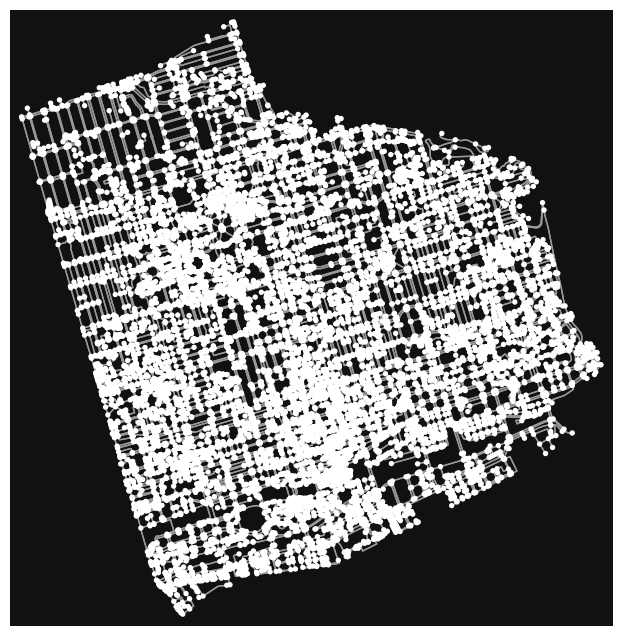

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [12]:
import matplotlib

ox.plot_graph(G_big, save=True, filepath="../visualize/downtown-toronto-graph.png", dpi=150)

### Validate the routing decision on real data this time

Found a real `wheelchair: no` edge with `find_edges_with_tag(G_big, "wheelchair", "no")`, then ran the same `length` vs `acc_weight` comparison as notebook 03's synthetic test — but this time on real OSM data, with `source`/`target` set to the two endpoints of the inaccessible edge itself, to see if a real alternative route exists and gets chosen.

In [15]:
no_access_edges = find_edges_with_tag(G_big, "wheelchair", "no")
print(no_access_edges[:3])

u_bad, v_bad, k_bad = no_access_edges[0]
print("testing around edge:", u_bad, "->", v_bad)

def accessibility_weight(attrs):
    base = attrs.get("length", 1)
    penalty = 0
    if attrs.get("wheelchair") == "no":
        penalty += 1000
    elif attrs.get("wheelchair") in ("yes", "designated"):
        penalty -= 2
    if attrs.get("surface") in ("gravel", "dirt", "grass", "ground"):
        penalty += 10
    return base + penalty

weights_big = {
    (u, v, k): accessibility_weight(data)
    for u, v, k, data in G_big.edges(keys=True, data=True)
}
nx.set_edge_attributes(G_big, weights_big, "acc_weight")

source = u_bad
target = v_bad

path_by_length = nx.shortest_path(G_big, source=source, target=target, weight="length")
path_by_acc = nx.shortest_path(G_big, source=source, target=target, weight="acc_weight")

print("shortest by length:", path_by_length)
print("shortest by acc_weight:", path_by_acc)
print("same route?", path_by_length == path_by_acc)

[(400707035, 516949102, 0), (419511967, 419511968, 0), (419511968, 419511967, 0)]
testing around edge: 400707035 -> 516949102
shortest by length: [400707035, 516949102]
shortest by acc_weight: [400707035, 3590076075, 3590076072, 6412492716, 516949102]
same route? False
